# PhageLysClass external application — manuscript panel (v6)

Publication-oriented visual update of the existing frozen A3/A4 application analyses. Panels A–F and all numerical calculations are unchanged. The display uses a more legible two-column / three-row composition, larger labels, and a differentiated, color-blind-conscious class palette. Reference and application points retain their original marker semantics. Figures are exported as high-resolution PNG and vector PDF.


In [1]:

from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.gridspec import GridSpec, GridSpecFromSubplotSpec
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

warnings.filterwarnings("ignore")

# ================================================================
# Visual style
# ================================================================
sns.set_theme(
    context="paper",
    style="white",
    font="DejaVu Sans",
    rc={
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.linewidth": 0.9,
        "axes.edgecolor": "#7F93A8",
        "xtick.color": "#3F5061",
        "ytick.color": "#3F5061",
        "axes.labelcolor": "#31465A",
        "text.color": "#31465A",
        "figure.facecolor": "white",
        "axes.facecolor": "white",
    },
)

mpl.rcParams.update({
    "font.size": 14.5,
    "axes.labelsize": 15.0,
    "axes.titlesize": 15.0,
    "xtick.labelsize": 12.8,
    "ytick.labelsize": 12.8,
    "legend.fontsize": 12.5,
})

LETTER_COLOR = "#315A84"
TEXT_COLOR = "#31465A"
GRID_COLOR = "#E3EAF0"

# Three lytic subclasses have distinct hues in every panel.
# Deeper blue: endolysins / global lytic; warm amber: depolymerases;
# turquoise: VAL. Background uses a quiet warm neutral.
COLORS = {
    "Lytic": "#3A73AF",
    "Non-lytic": "#E6C5B7",
    "Endolysin": "#3A73AF",
    "Depolymerase": "#DB9452",
    "VAL": "#269C91",
}

SOURCE_ORDER = [
    "phagelys_prediction_extension",
    "zymctrl",
    "ambiguous_structural",
]

SOURCE_LABELS = {
    "phagelys_prediction_extension": "Prediction Extension",
    "zymctrl": "ZymCTRL",
    "ambiguous_structural": "Ambiguous structural",
}

FUNCTION_ORDER = ["endolysin", "depolymerase", "val"]

FUNCTION_LABELS = {
    "endolysin": "Endolysin",
    "depolymerase": "Depolymerase",
    "val": "VAL",
}

# Sequential reference-support scale; light low values and saturated high values.
# More visible gradations than the original blue-only palette.
HEATMAP_CMAP = sns.blend_palette(
    ["#F8F9FB", "#D2E5E8", "#7BBFBB", "#417FAC", "#6650A0"],
    as_cmap=True,
)

def discover_project_root() -> Path:
    cwd = Path.cwd().resolve()
    for root in [cwd, *cwd.parents]:
        if (root / "analysis_explored_seqs").is_dir():
            return root
    raise FileNotFoundError(
        "Could not locate the project root containing analysis_explored_seqs/."
    )

PROJECT_ROOT = discover_project_root()

A3_DIR = PROJECT_ROOT / "analysis_explored_seqs" / "A3_reference_geometry" / "tables"
A4_DIR = PROJECT_ROOT / "analysis_explored_seqs" / "A4_prediction_geometry_integration"
A4_TABLES = A4_DIR / "tables"
A4_FIGURES = A4_DIR / "figures"
A4_FIGURES.mkdir(parents=True, exist_ok=True)

def require_file(path: Path) -> Path:
    if not path.is_file():
        raise FileNotFoundError(f"Required file not found: {path}")
    return path

def canonical_function(value):
    if pd.isna(value):
        return None
    x = str(value).strip().lower()
    return {
        "endolysin": "endolysin",
        "depolymerase": "depolymerase",
        "dpo": "depolymerase",
        "val": "val",
        "virion_associated_lytic_enzyme": "val",
        "virion-associated lytic enzyme": "val",
    }.get(x)

def add_panel_letter(ax, letter, x=-0.12, y=1.04):
    ax.text(
        x, y, letter,
        transform=ax.transAxes,
        ha="left", va="bottom",
        fontsize=23,
        fontweight="bold",
        color=LETTER_COLOR,
        zorder=50,
    )

def style_axis(ax, grid=False, axis="y"):
    if grid:
        ax.grid(True, axis=axis, color=GRID_COLOR, linewidth=0.8, alpha=0.84)
    else:
        ax.grid(False)
    sns.despine(ax=ax)

def save_figure(fig, stem: Path):
    fig.savefig(stem.with_suffix(".png"), dpi=300, bbox_inches="tight", facecolor="white")
    fig.savefig(stem.with_suffix(".pdf"), bbox_inches="tight", facecolor="white")

print("Project root :", PROJECT_ROOT)
print("A3 tables    :", A3_DIR)
print("A4 tables    :", A4_TABLES)
print("Figure output:", A4_FIGURES)


Project root : /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass
A3 tables    : /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/analysis_explored_seqs/A3_reference_geometry/tables
A4 tables    : /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/analysis_explored_seqs/A4_prediction_geometry_integration/tables
Figure output: /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/analysis_explored_seqs/A4_prediction_geometry_integration/figures


In [2]:

# ================================================================
# Load frozen outputs
# ================================================================
master = pd.read_csv(
    require_file(A4_TABLES / "external_prediction_property_geometry_master.tsv.gz"),
    sep="\t",
    compression="infer",
    low_memory=False,
)

source_class_summary = pd.read_csv(
    require_file(A4_TABLES / "integration_summary_by_source_class.tsv"),
    sep="\t",
    low_memory=False,
)

source_class_summary["predicted_class"] = (
    source_class_summary["predicted_class"].map(canonical_function)
)

tsne_parts = []
for source in SOURCE_ORDER:
    x = pd.read_csv(
        require_file(A3_DIR / f"tsne_{source}_coordinates.tsv.gz"),
        sep="\t",
        compression="infer",
        low_memory=False,
    )
    x["tsne_source"] = source
    tsne_parts.append(x)

tsne = pd.concat(tsne_parts, ignore_index=True)

if "functional_class" not in tsne.columns:
    helper = master[["analysis_id", "functional_class_a4"]].drop_duplicates("analysis_id")
    tsne = tsne.merge(helper, on="analysis_id", how="left")
    tsne["functional_class"] = tsne["functional_class_a4"].map(canonical_function)

if "origin" not in tsne.columns:
    tsne["origin"] = np.where(tsne["analysis_id"].isna(), "Reference", "External")

tsne["functional_class"] = tsne["functional_class"].map(canonical_function)

print(f"Integrated sequences: {len(master):,}")
print(f"Predicted lytic: {(master['global_prediction'] == 'lytic').sum():,}")
print(f"t-SNE rows: {len(tsne):,}")


Integrated sequences: 77,897
Predicted lytic: 58,984
t-SNE rows: 17,998


In [3]:

# ================================================================
# Prepare panel data
# ================================================================

# A — global composition
source_counts = (
    master.groupby(["source", "global_prediction"])
    .size()
    .rename("n")
    .reset_index()
)

source_totals = (
    source_counts.groupby("source")["n"]
    .sum()
    .rename("total")
    .reset_index()
)

global_pivot = (
    source_counts.pivot(index="source", columns="global_prediction", values="n")
    .reindex(SOURCE_ORDER)
    .fillna(0)
)

global_pivot["total"] = global_pivot.sum(axis=1)
global_pivot["lytic_fraction"] = global_pivot["lytic"] / global_pivot["total"]
global_pivot["non_lytic_fraction"] = global_pivot["non_lytic_background"] / global_pivot["total"]

# B — subtype composition
lytic = master[master["global_prediction"] == "lytic"].copy()
lytic["functional_class"] = lytic["functional_class_a4"].map(canonical_function)

functional_counts = (
    lytic.groupby(["source", "functional_class"])
    .size()
    .rename("n")
    .reset_index()
)

functional_counts["fraction"] = (
    functional_counts["n"]
    / functional_counts.groupby("source")["n"].transform("sum")
)

functional_pivot = (
    functional_counts.pivot(
        index="source",
        columns="functional_class",
        values="fraction",
    )
    .reindex(index=SOURCE_ORDER, columns=FUNCTION_ORDER)
    .fillna(0.0)
)

# F — integrated support matrix
def build_support_matrix(summary: pd.DataFrame) -> pd.DataFrame:
    df = summary.copy()
    df["row"] = (
        df["source"].map(SOURCE_LABELS)
        + " — "
        + df["predicted_class"].map(FUNCTION_LABELS)
    )

    metrics = {
        "Property\nsupport": "property_supported_fraction",
        "Subtype\ncoverage": "geometry_coverage95_fraction",
        "Local geometry\nagreement": "local_geometry_supported_fraction",
        "Full\nconcordance": "concordant_fraction",
    }

    rows = []
    for _, r in df.iterrows():
        for metric_label, col in metrics.items():
            rows.append({
                "row": r["row"],
                "metric": metric_label,
                "value": 100.0 * r[col],
            })

    long = pd.DataFrame(rows)
    matrix = long.pivot(index="row", columns="metric", values="value")

    ordered_rows = []
    for source in SOURCE_ORDER:
        for cls in FUNCTION_ORDER:
            label = f"{SOURCE_LABELS[source]} — {FUNCTION_LABELS[cls]}"
            if label in matrix.index:
                ordered_rows.append(label)

    return matrix.reindex(
        index=ordered_rows,
        columns=list(metrics.keys()),
    )

support_matrix = build_support_matrix(source_class_summary)

display(global_pivot[["lytic", "non_lytic_background", "total"]])
display(functional_pivot)
display(support_matrix)


global_prediction,lytic,non_lytic_background,total
source,,,
phagelys_prediction_extension,47797,10487,58284
zymctrl,6952,3048,10000
ambiguous_structural,4235,5378,9613


functional_class,endolysin,depolymerase,val
source,,,
phagelys_prediction_extension,0.992636,0.000251,0.007113
zymctrl,0.910386,0.070483,0.019131
ambiguous_structural,0.238489,0.672491,0.089020


metric,Property\nsupport,Subtype\ncoverage,Local geometry\nagreement,Full\nconcordance
row,,,,
Prediction Extension — Endolysin,85.705554,60.006323,92.397513,54.189061
Prediction Extension — Depolymerase,75.000000,58.333333,50.000000,33.333333
Prediction Extension — VAL,80.588235,70.294118,20.588235,18.529412
ZymCTRL — Endolysin,39.996839,29.377370,84.955752,27.402023
ZymCTRL — Depolymerase,29.183673,29.591837,56.734694,9.387755
ZymCTRL — VAL,0.000000,0.000000,0.000000,0.000000
Ambiguous structural — Endolysin,84.455446,48.613861,59.009901,30.198020
Ambiguous structural — Depolymerase,90.063202,91.186798,74.754213,65.905899
Ambiguous structural — VAL,90.450928,67.904509,35.809019,35.278515


In [4]:

# ================================================================
# Plot helpers
# ================================================================

def draw_global_stacked_panel(ax):
    """
    Panel A: global lytic / non-lytic composition.

    Source size is integrated directly into the x tick label to avoid
    collisions between the separate n annotation and the source name.
    """
    x = np.arange(len(SOURCE_ORDER))

    lytic = 100.0 * global_pivot["lytic_fraction"].to_numpy(dtype=float)
    non_lytic = 100.0 * global_pivot["non_lytic_fraction"].to_numpy(dtype=float)
    totals = global_pivot["total"].to_numpy(dtype=int)

    ax.bar(
        x,
        lytic,
        width=0.68,
        color=COLORS["Lytic"],
        edgecolor="white",
        linewidth=0.9,
        label="Lytic",
    )

    ax.bar(
        x,
        non_lytic,
        bottom=lytic,
        width=0.68,
        color=COLORS["Non-lytic"],
        edgecolor="white",
        linewidth=0.9,
        label="Non-lytic",
    )

    for i, (lf, nf) in enumerate(zip(lytic, non_lytic)):
        ax.text(
            i,
            lf / 2,
            f"{lf:.1f}%",
            ha="center",
            va="center",
            fontsize=15.0,
            color="white" if lf > 18 else TEXT_COLOR,
            fontweight="bold",
        )

        if nf >= 4:
            ax.text(
                i,
                lf + nf / 2,
                f"{nf:.1f}%",
                ha="center",
                va="center",
                fontsize=14.0,
                color=TEXT_COLOR,
            )

    ax.set_ylim(0, 107)
    ax.set_ylabel("Composition (%)")
    ax.set_xticks(x)

    ax.set_xticklabels(
        [
            f"Prediction\nExtension\nn={totals[0]:,}",
            f"ZymCTRL\nn={totals[1]:,}",
            f"Ambiguous\nstructural\nn={totals[2]:,}",
        ],
        fontsize=12.6,
        linespacing=1.15,
    )

    ax.tick_params(
        axis="x",
        pad=7,
    )

    ax.legend(
        frameon=False,
        loc="lower right",
        bbox_to_anchor=(1.0, 1.012),
        ncol=2,
        columnspacing=1.4,
        handlelength=1.2,
    )

    style_axis(
        ax,
        grid=True,
        axis="y",
    )

def draw_stacked_panel(ax):
    x = np.arange(len(SOURCE_ORDER))
    bottom = np.zeros(len(SOURCE_ORDER), dtype=float)

    for cls in FUNCTION_ORDER:
        label = FUNCTION_LABELS[cls]
        values = 100.0 * functional_pivot[cls].to_numpy(dtype=float)

        ax.bar(
            x, values,
            bottom=bottom,
            width=0.68,
            color=COLORS[label],
            edgecolor="white",
            linewidth=0.9,
            label=label,
        )

        for xpos, value, base in zip(x, values, bottom):
            if value >= 5.0:
                ax.text(
                    xpos, base + value / 2.0,
                    f"{value:.1f}%",
                    ha="center", va="center",
                    fontsize=14.4,
                    color="white" if value > 20 else TEXT_COLOR,
                    fontweight="bold" if value > 20 else None,
                )
            elif value >= 0.4:
                ax.text(
                    xpos, base + value + 1.1,
                    f"{value:.1f}%",
                    ha="center", va="bottom",
                    fontsize=12.0,
                    color=TEXT_COLOR,
                )

        bottom += values

    ax.set_ylim(0, 107)
    ax.set_ylabel("Composition (%)")
    ax.set_xticks(x)
    ax.set_xticklabels(
        ["Prediction\nExtension", "ZymCTRL", "Ambiguous\nstructural"]
    )

    ax.legend(
        title="",
        frameon=False,
        loc="lower right",
        bbox_to_anchor=(1.0, 1.012),
        ncol=3,
        columnspacing=1.3,
        handlelength=1.1,
    )

    style_axis(ax, grid=True, axis="y")


def draw_tsne_panel(ax, source):
    t = tsne[tsne["tsne_source"] == source].copy()
    t = t[t["functional_class"].notna()].copy()
    t["functional_label"] = t["functional_class"].map(FUNCTION_LABELS)

    reference = t[t["origin"].astype(str).str.lower() == "reference"].copy()
    external = t[t["origin"].astype(str).str.lower() != "reference"].copy()

    hue_order = [FUNCTION_LABELS[c] for c in FUNCTION_ORDER]
    palette = {k: COLORS[k] for k in hue_order}

    if not reference.empty:
        sns.scatterplot(
            data=reference,
            x="TSNE1",
            y="TSNE2",
            hue="functional_label",
            hue_order=hue_order,
            palette=palette,
            marker="o",
            s=23,
            alpha=0.23,
            linewidth=0,
            legend=False,
            ax=ax,
        )

    if not external.empty:
        sns.scatterplot(
            data=external,
            x="TSNE1",
            y="TSNE2",
            hue="functional_label",
            hue_order=hue_order,
            palette=palette,
            marker="X",
            s=29,
            alpha=0.79,
            linewidth=0,
            legend=False,
            ax=ax,
        )

    ax.set_xlabel("t-SNE1")
    ax.set_ylabel("t-SNE2")
    ax.margins(x=0.035, y=0.035)
    style_axis(ax, grid=True, axis="both")


def draw_support_heatmap(ax_labels, ax_heat, ax_cbar):
    """
    Panel F with row labels, heatmap body and colorbar on independent axes.
    This prevents long row labels from consuming the heatmap plotting width.
    """
    matrix = support_matrix.copy()

    hm = sns.heatmap(
        matrix,
        vmin=0,
        vmax=100,
        cmap=HEATMAP_CMAP,
        annot=True,
        fmt=".1f",
        linewidths=0.55,
        linecolor="white",
        annot_kws={"fontsize": 10.8},
        yticklabels=False,
        cbar=True,
        cbar_ax=ax_cbar,
        cbar_kws={"label": "Sequences (%)"},
        ax=ax_heat,
    )

    # Strong contrast for the numerical cell annotations.
    for text_artist, value in zip(ax_heat.texts, matrix.to_numpy().ravel()):
        if np.isfinite(value):
            text_artist.set_color("white" if value >= 66 else TEXT_COLOR)
            text_artist.set_fontweight("bold" if value >= 66 else "normal")

    # Heatmap body
    ax_heat.set_xlabel("")
    ax_heat.set_ylabel("")
    ax_heat.tick_params(
        axis="x",
        rotation=0,
        labelsize=12.5,
        pad=6,
    )
    ax_heat.tick_params(
        axis="y",
        left=False,
        labelleft=False,
    )

    # Dedicated row-label axis
    ax_labels.set_xlim(0, 1)
    ax_labels.set_ylim(len(matrix), 0)
    ax_labels.axis("off")

    for i, label in enumerate(matrix.index):
        compact = (
            label
            .replace("Prediction Extension", "Prediction Ext.")
            .replace("Ambiguous structural", "Ambiguous")
        )

        ax_labels.text(
            0.98,
            i + 0.5,
            compact,
            ha="right",
            va="center",
            fontsize=11.8,
            color=TEXT_COLOR,
        )

    # Colorbar
    ax_cbar.tick_params(
        labelsize=12.0,
        colors=TEXT_COLOR,
    )
    ax_cbar.yaxis.label.set_color(TEXT_COLOR)
    ax_cbar.yaxis.label.set_size(13.0)


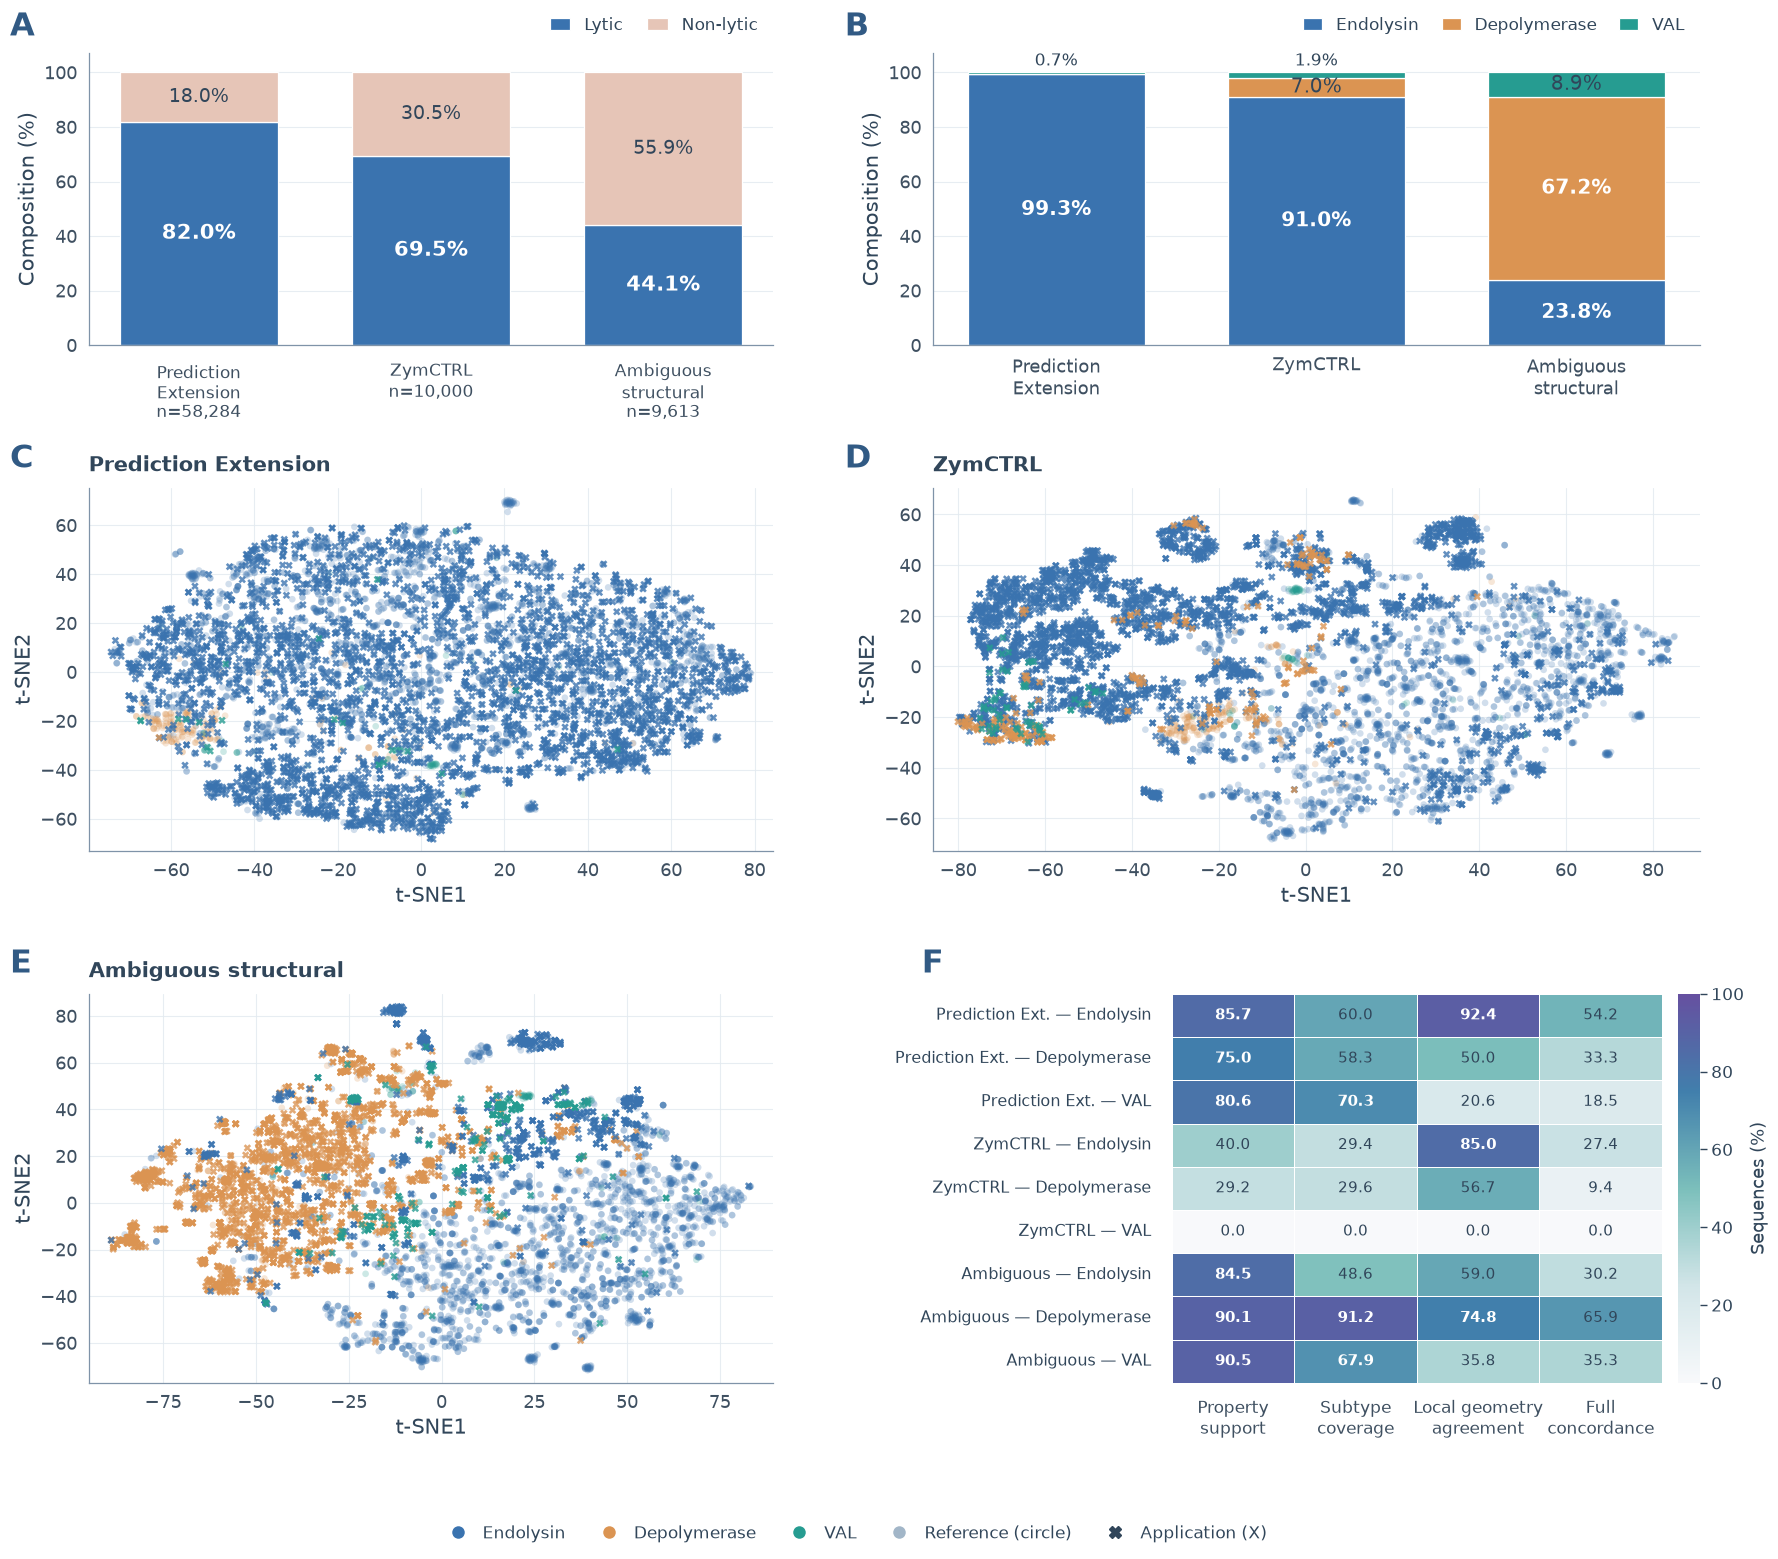

Saved manuscript figure:
 - /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/analysis_explored_seqs/A4_prediction_geometry_integration/figures/Figure_final_external_application_FINAL_v6.png
 - /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/analysis_explored_seqs/A4_prediction_geometry_integration/figures/Figure_final_external_application_FINAL_v6.pdf


In [5]:
# ================================================================
# Final manuscript figure — v6 (larger, clearer, less monochromatic)
# ================================================================
#
# A | B  : source composition and conditional subtype composition
# C | D  : t-SNE, Prediction Extension and ZymCTRL
# E | F  : t-SNE, ambiguous structural and reference-space support
#
# The 2-column arrangement gives axes enough physical width for
# journal-scale labels; the support heatmap keeps separate row-label
# and colorbar axes to prevent compressing the numerical cells.

fig = plt.figure(figsize=(17.8, 16.0), facecolor="white")

gs = GridSpec(
    3, 2, figure=fig,
    width_ratios=[1.0, 1.12],
    height_ratios=[0.90, 1.12, 1.20],
    wspace=0.22,
    hspace=0.41,
)

axA = fig.add_subplot(gs[0, 0])
axB = fig.add_subplot(gs[0, 1])
axC = fig.add_subplot(gs[1, 0])
axD = fig.add_subplot(gs[1, 1])
axE = fig.add_subplot(gs[2, 0])

f_gs = GridSpecFromSubplotSpec(
    1, 3, subplot_spec=gs[2, 1],
    width_ratios=[1.75, 3.85, 0.17],
    wspace=0.065,
)
axF_labels = fig.add_subplot(f_gs[0, 0])
axF_heat = fig.add_subplot(f_gs[0, 1])
axF_cbar = fig.add_subplot(f_gs[0, 2])

# Frozen data, unchanged panel calculations.
draw_global_stacked_panel(axA)
draw_stacked_panel(axB)
draw_tsne_panel(axC, "phagelys_prediction_extension")
draw_tsne_panel(axD, "zymctrl")
draw_tsne_panel(axE, "ambiguous_structural")
draw_support_heatmap(axF_labels, axF_heat, axF_cbar)

# Explicit source labels clarify which application collection is shown.
for axis, heading in [
    (axC, "Prediction Extension"),
    (axD, "ZymCTRL"),
    (axE, "Ambiguous structural"),
]:
    axis.set_title(heading, fontsize=15, fontweight="bold", loc="left", pad=12, color=TEXT_COLOR)

for axis, label, xpos in [
    (axA, "A", -0.115),
    (axB, "B", -0.115),
    (axC, "C", -0.115),
    (axD, "D", -0.115),
    (axE, "E", -0.115),
    (axF_labels, "F", -0.05),
]:
    add_panel_letter(axis, label, x=xpos, y=1.035)

# Shared legend for the t-SNE panels: subclass color and point origin.
geometry_handles = [
    Line2D([0], [0], marker="o", linestyle="None",
           markerfacecolor=COLORS["Endolysin"], markeredgecolor="none",
           markersize=9, label="Endolysin"),
    Line2D([0], [0], marker="o", linestyle="None",
           markerfacecolor=COLORS["Depolymerase"], markeredgecolor="none",
           markersize=9, label="Depolymerase"),
    Line2D([0], [0], marker="o", linestyle="None",
           markerfacecolor=COLORS["VAL"], markeredgecolor="none",
           markersize=9, label="VAL"),
    Line2D([0], [0], marker="o", linestyle="None",
           markerfacecolor="#A2B6C8", markeredgecolor="none",
           markersize=9, label="Reference (circle)"),
    Line2D([0], [0], marker="X", linestyle="None",
           color=TEXT_COLOR, markersize=9, label="Application (X)"),
]

fig.legend(
    handles=geometry_handles,
    loc="lower center",
    bbox_to_anchor=(0.5, 0.016),
    ncol=5, frameon=False, fontsize=12.0,
    handletextpad=0.5, columnspacing=1.6,
)

fig.subplots_adjust(left=0.070, right=0.975, top=0.956, bottom=0.125)

OUTPUT_STEM = A4_FIGURES / "Figure_final_external_application_FINAL_v6"
save_figure(fig, OUTPUT_STEM)
plt.show()

print("Saved manuscript figure:")
print(" -", OUTPUT_STEM.with_suffix(".png"))
print(" -", OUTPUT_STEM.with_suffix(".pdf"))


## Notes

The notebook reads the same frozen A3/A4 source tables as v5. No analysis, data filtering, thresholds, or percentages were changed. The updated panel is a visualization-only revision. Run in the original project environment to produce the real-data PNG and vector PDF.
